some trained models:

18_2. model_1: SquareGMM of Simon, feat=80, inflate_full=True, delta=0.01, max_feature_dim=80, max_model_dim=80, prior.gmm.max_num_cluster=80, EPOCHS=50, BATCH_SIZE=2

18. model_2: SquareGMM of Simon, feat=80, inflate_full=True, delta=0.01, max_feature_dim=80, max_model_dim=80, prior.gmm.max_num_cluster=80, EPOCHS=50, BATCH_SIZE=4

18_2. model_3: SquareGMM of Simon, feat=80, inflate_full=True, delta=0.01, max_feature_dim=80, max_model_dim=80, prior.gmm.max_num_cluster=80, EPOCHS=50, BATCH_SIZE=6


# NEW
4. model_4: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=50, BATCH_SIZE=2, train.nlayer=4

5. model_5: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=50, BATCH_SIZE=4, train.nlayer=4

6. model_6: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=50, BATCH_SIZE=6, train.nlayer=4

# Trained:
7. model_7: SquareGMM of Simon, feat=70, inflate_full=True, delta=0.01, max_feature_dim=70, max_model_dim=70, prior.gmm.max_num_cluster=70, EPOCHS=50, BATCH_SIZE=2

22. model_22: SquareGMM of Simon, feat=70, inflate_full=True, delta=0.01, max_feature_dim=70, max_model_dim=70, prior.gmm.max_num_cluster=70, EPOCHS=50, BATCH_SIZE=4

24. model_24: SquareGMM of Simon, feat=70, inflate_full=True, delta=0.01, max_feature_dim=70, max_model_dim=70, prior.gmm.max_num_cluster=70, EPOCHS=50, BATCH_SIZE=6


https://neptune.ai/blog/f1-score-accuracy-roc-auc-pr-auc

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import torch

In [2]:
# paths of models
model_1_dir = "../results/adbench/dataSGMM.context5000.feat80.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs2.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters80/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_2_dir = "../results/adbench/context5000.feat80.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_3_dir = "../results/adbench/context5000.feat80.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"

model_1_dir_loss = "../ckpt/dataSGMM.context5000.feat80.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs2.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters80/seed0/train_val_loss.pickle"
model_2_dir_loss = "../ckpt/context5000.feat80.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/seed0/train_val_loss.pickle"
model_3_dir_loss = "../ckpt/context5000.feat80.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/seed0/train_val_loss.pickle"

model_4_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs2.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_5_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_6_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"

model_4_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs2.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_5_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_6_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"

model_7_dir = "../results/adbench/dataBATCHSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs2.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters70/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_8_dir = "../results/adbench/context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_9_dir = "../results/adbench/context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"

model_7_dir_loss = "../ckpt/dataBATCHSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs2.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters70/seed0/train_val_loss.pickle"
model_8_dir_loss = "../ckpt/context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/seed0/train_val_loss.pickle"
model_9_dir_loss = "../ckpt/context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/seed0/train_val_loss.pickle"


### 1. Model_1

In [3]:
with open(model_1_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_1 = data["train_loss"]
val_loss_1 = data["val_loss"]
model_1_train_time = data['train_time']

print("Train time in second", model_1_train_time)
model_1_aucroc_scores = []
model_1_aucpr_scores = []
model_1_f1_scores = []
model_1_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_1_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_1_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_1_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_1_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_1_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_1_avg_aucroc = sum(model_1_aucroc_scores) / len(model_1_aucroc_scores)
model_1_avg_aucpr = sum(model_1_aucpr_scores) / len(model_1_aucpr_scores)
model_1_avg_f1 = sum(model_1_f1_scores) / len(model_1_f1_scores)
model_1_time_per_instance_avg = sum(model_1_time_per_instance) / len(model_1_time_per_instance)

print(f"number of datasets: {len(model_1_aucroc_scores)}")
print(f"Average aucroc: {model_1_avg_aucroc}")
print(f"Average aucpr: {model_1_avg_aucpr}")
print(f"Average f1: {model_1_avg_f1}")
print(f"Inference time per instance: {model_1_time_per_instance_avg}")

Train time in second 10079.90102815628
number of datasets: 121
Average aucroc: 0.7631854054954075
Average aucpr: 0.4394093859888194
Average f1: 0.44648014938142866
Inference time per instance: 4.938330807906365e-06


### 2. Model_2

In [4]:
with open(model_2_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_2 = data["train_loss"]
val_loss_2 = data["val_loss"]
model_2_train_time = data['train_time']

print("Train time in second", model_2_train_time)
model_2_aucroc_scores = []
model_2_aucpr_scores = []
model_2_f1_scores = []
model_2_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_2_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_2_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_2_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_2_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_2_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_2_avg_aucroc = sum(model_2_aucroc_scores) / len(model_2_aucroc_scores)
model_2_avg_aucpr = sum(model_2_aucpr_scores) / len(model_2_aucpr_scores)
model_2_avg_f1 = sum(model_2_f1_scores) / len(model_2_f1_scores)
model_2_time_per_instance_avg = sum(model_2_time_per_instance) / len(model_2_time_per_instance)

print(f"number of datasets: {len(model_2_aucroc_scores)}")
print(f"Average aucroc: {model_2_avg_aucroc}")
print(f"Average aucpr: {model_2_avg_aucpr}")
print(f"Average f1: {model_2_avg_f1}")
print(f"Inference time per instance: {model_2_time_per_instance_avg}")

Train time in second 27951.29672217369
number of datasets: 121
Average aucroc: 0.7664115769172253
Average aucpr: 0.44113147204850495
Average f1: 0.4421199694683027
Inference time per instance: 5.023406086278049e-06


### 4. Model_3

In [5]:
with open(model_3_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_3 = data["train_loss"]
val_loss_3 = data["val_loss"]
model_3_train_time = data['train_time']

print("Train time in second", model_3_train_time)
model_3_aucroc_scores = []
model_3_aucpr_scores = []
model_3_f1_scores = []
model_3_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_3_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_3_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_3_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_3_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_3_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_3_avg_aucroc = sum(model_3_aucroc_scores) / len(model_3_aucroc_scores)
model_3_avg_aucpr = sum(model_3_aucpr_scores) / len(model_3_aucpr_scores)
model_3_avg_f1 = sum(model_3_f1_scores) / len(model_3_f1_scores)
model_3_time_per_instance_avg = sum(model_3_time_per_instance) / len(model_3_time_per_instance)

print(f"number of datasets: {len(model_3_aucroc_scores)}")
print(f"Average aucroc: {model_3_avg_aucroc}")
print(f"Average aucpr: {model_3_avg_aucpr}")
print(f"Average f1: {model_3_avg_f1}")
print(f"Inference time per instance: {model_3_time_per_instance_avg}")

Train time in second 35570.752393484116
number of datasets: 121
Average aucroc: 0.7629311753338073
Average aucpr: 0.44349458334092523
Average f1: 0.4461905725516321
Inference time per instance: 5.075238669516644e-06


### 4. Model_4

In [6]:
with open(model_4_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_4 = data["train_loss"]
val_loss_4 = data["val_loss"]
model_4_train_time = data['train_time']

print("Train time in second", model_4_train_time)
model_4_aucroc_scores = []
model_4_aucpr_scores = []
model_4_f1_scores = []
model_4_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_4_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_4_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_4_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_4_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_4_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_4_avg_aucroc = sum(model_4_aucroc_scores) / len(model_4_aucroc_scores)
model_4_avg_aucpr = sum(model_4_aucpr_scores) / len(model_4_aucpr_scores)
model_4_avg_f1 = sum(model_4_f1_scores) / len(model_4_f1_scores)
model_4_time_per_instance_avg = sum(model_4_time_per_instance) / len(model_4_time_per_instance)

print(f"number of datasets: {len(model_4_aucroc_scores)}")
print(f"Average aucroc: {model_4_avg_aucroc}")
print(f"Average aucpr: {model_4_avg_aucpr}")
print(f"Average f1: {model_4_avg_f1}")
print(f"Inference time per instance: {model_4_time_per_instance_avg}")

Train time in second 4814.375986814499
number of datasets: 121
Average aucroc: 0.7262158966504338
Average aucpr: 0.4351813329992632
Average f1: 0.4277886244731594
Inference time per instance: 4.8712117970828e-06


### 5. model_5

In [7]:
with open(model_5_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_5 = data["train_loss"]
val_loss_5 = data["val_loss"]
model_5_train_time = data['train_time']

print("Train time in second", model_5_train_time)
model_5_aucroc_scores = []
model_5_aucpr_scores = []
model_5_f1_scores = []
model_5_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_5_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_5_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_5_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_5_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_5_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_5_avg_aucroc = sum(model_5_aucroc_scores) / len(model_5_aucroc_scores)
model_5_avg_aucpr = sum(model_5_aucpr_scores) / len(model_5_aucpr_scores)
model_5_avg_f1 = sum(model_5_f1_scores) / len(model_5_f1_scores)
model_5_time_per_instance_avg = sum(model_5_time_per_instance) / len(model_5_time_per_instance)

print(f"number of datasets: {len(model_5_aucroc_scores)}")
print(f"Average aucroc: {model_5_avg_aucroc}")
print(f"Average aucpr: {model_5_avg_aucpr}")
print(f"Average f1: {model_5_avg_f1}")
print(f"Inference time per instance: {model_5_time_per_instance_avg}")

Train time in second 12389.380487203598
number of datasets: 121
Average aucroc: 0.7345388146882167
Average aucpr: 0.40800228946261774
Average f1: 0.40846239936904655
Inference time per instance: 5.034104464394643e-06


### 6. model_6

In [8]:
with open(model_6_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_6 = data["train_loss"]
val_loss_6 = data["val_loss"]
model_6_train_time = data['train_time']

print("Train time in second", model_6_train_time)
model_6_aucroc_scores = []
model_6_aucpr_scores = []
model_6_f1_scores = []
model_6_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_6_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_6_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_6_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_6_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_6_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_6_avg_aucroc = sum(model_6_aucroc_scores) / len(model_6_aucroc_scores)
model_6_avg_aucpr = sum(model_6_aucpr_scores) / len(model_6_aucpr_scores)
model_6_avg_f1 = sum(model_6_f1_scores) / len(model_6_f1_scores)
model_6_time_per_instance_avg = sum(model_6_time_per_instance) / len(model_6_time_per_instance)

print(f"number of datasets: {len(model_6_aucroc_scores)}")
print(f"Average aucroc: {model_6_avg_aucroc}")
print(f"Average aucpr: {model_6_avg_aucpr}")
print(f"Average f1: {model_6_avg_f1}")
print(f"Inference time per instance: {model_6_time_per_instance_avg}")

Train time in second 13037.650875329971
number of datasets: 121
Average aucroc: 0.7268812615980993
Average aucpr: 0.39912196671328987
Average f1: 0.39165298250499414
Inference time per instance: 4.9081005605499e-06


### 7. model_7

In [9]:
with open(model_7_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_7 = data["train_loss"]
val_loss_7 = data["val_loss"]
model_7_train_time = data['train_time']

print("Train time in second", model_7_train_time)
model_7_aucroc_scores = []
model_7_aucpr_scores = []
model_7_f1_scores = []
model_7_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_7_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_7_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_7_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_7_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_7_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_7_avg_aucroc = sum(model_7_aucroc_scores) / len(model_7_aucroc_scores)
model_7_avg_aucpr = sum(model_7_aucpr_scores) / len(model_7_aucpr_scores)
model_7_avg_f1 = sum(model_7_f1_scores) / len(model_7_f1_scores)
model_7_time_per_instance_avg = sum(model_7_time_per_instance) / len(model_7_time_per_instance)

print(f"number of datasets: {len(model_7_aucroc_scores)}")
print(f"Average aucroc: {model_7_avg_aucroc}")
print(f"Average aucpr: {model_7_avg_aucpr}")
print(f"Average f1: {model_7_avg_f1}")
print(f"Inference time per instance: {model_7_time_per_instance_avg}")

Train time in second 7831.280224561691
number of datasets: 121
Average aucroc: 0.7640916113083694
Average aucpr: 0.44520592256695174
Average f1: 0.444841603315459
Inference time per instance: 4.8915238876561825e-06


### 8. model_8

In [10]:
with open(model_8_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_8 = data["train_loss"]
val_loss_8 = data["val_loss"]
model_8_train_time = data['train_time']

print("Train time in second", model_8_train_time)
model_8_aucroc_scores = []
model_8_aucpr_scores = []
model_8_f1_scores = []
model_8_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_8_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_8_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_8_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_8_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_8_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_8_avg_aucroc = sum(model_8_aucroc_scores) / len(model_8_aucroc_scores)
model_8_avg_aucpr = sum(model_8_aucpr_scores) / len(model_8_aucpr_scores)
model_8_avg_f1 = sum(model_8_f1_scores) / len(model_8_f1_scores)
model_8_time_per_instance_avg = sum(model_8_time_per_instance) / len(model_8_time_per_instance)

print(f"number of datasets: {len(model_8_aucroc_scores)}")
print(f"Average aucroc: {model_8_avg_aucroc}")
print(f"Average aucpr: {model_8_avg_aucpr}")
print(f"Average f1: {model_8_avg_f1}")
print(f"Inference time per instance: {model_8_time_per_instance_avg}")

Train time in second 17772.96105003357
number of datasets: 121
Average aucroc: 0.7692643131977385
Average aucpr: 0.44905888404148675
Average f1: 0.4493582619772472
Inference time per instance: 5.099698427791145e-06


### 9. model_9

In [11]:
with open(model_9_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_9 = data["train_loss"]
val_loss_9 = data["val_loss"]
model_9_train_time = data['train_time']

print("Train time in second", model_9_train_time)
model_9_aucroc_scores = []
model_9_aucpr_scores = []
model_9_f1_scores = []
model_9_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_9_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_9_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_9_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_9_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_9_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_9_avg_aucroc = sum(model_9_aucroc_scores) / len(model_9_aucroc_scores)
model_9_avg_aucpr = sum(model_9_aucpr_scores) / len(model_9_aucpr_scores)
model_9_avg_f1 = sum(model_9_f1_scores) / len(model_9_f1_scores)
model_9_time_per_instance_avg = sum(model_9_time_per_instance) / len(model_9_time_per_instance)

print(f"number of datasets: {len(model_9_aucroc_scores)}")
print(f"Average aucroc: {model_9_avg_aucroc}")
print(f"Average aucpr: {model_9_avg_aucpr}")
print(f"Average f1: {model_9_avg_f1}")
print(f"Inference time per instance: {model_9_time_per_instance_avg}")

Train time in second 24438.818897247314
number of datasets: 121
Average aucroc: 0.7697659957547673
Average aucpr: 0.4490145093473653
Average f1: 0.4497923147876835
Inference time per instance: 5.1106435673690565e-06


### Visualization

In [12]:
models = ['Model_1', 'Model_2', 'Model_3', 'Model_7', 'Model_8', 'Model_9', 'Model_4', 'Model_5', 'Model_6']
max_feat_dim = ['80', '80', '80', '70', '70', '70', '20', '20', '20',]
batch_size = ['2', '4', '6', '2', '4', '6', '2', '4', '6']
avg_aucroc_scores = [round(model_1_avg_aucroc, 4), round(model_2_avg_aucroc, 4), round(model_3_avg_aucroc, 4), round(model_7_avg_aucroc, 4), round(model_8_avg_aucroc, 4), round(model_9_avg_aucroc, 4), round(model_4_avg_aucroc, 4), round(model_5_avg_aucroc, 4), round(model_6_avg_aucroc, 4)]
avg_aucpr_scores = [round(model_1_avg_aucpr, 4), round(model_2_avg_aucpr, 4), round(model_3_avg_aucpr, 4), round(model_7_avg_aucpr, 4), round(model_8_avg_aucpr, 4), round(model_9_avg_aucpr, 4), round(model_4_avg_aucpr, 4), round(model_5_avg_aucpr, 4), round(model_6_avg_aucpr, 4)]
avg_f1_scores = [round(model_1_avg_f1, 4), round(model_2_avg_f1, 4), round(model_3_avg_f1, 4), round(model_7_avg_f1, 4), round(model_8_avg_f1, 4), round(model_9_avg_f1, 4), round(model_4_avg_f1, 4), round(model_5_avg_f1, 4), round(model_6_avg_f1, 4)]

# training time is in seconds
training_time = [round(model_1_train_time, 2), round(model_2_train_time, 2), round(model_3_train_time, 2), round(model_7_train_time, 2), round(model_8_train_time, 2), round(model_9_train_time, 2), round(model_4_train_time, 2), round(model_5_train_time, 2), round(model_6_train_time, 2)]
# inference time is in microseconds (µs)
inference_time = [model_1_time_per_instance_avg * 1e6, model_2_time_per_instance_avg * 1e6, model_3_time_per_instance_avg * 1e6, model_7_time_per_instance_avg * 1e6, model_8_time_per_instance_avg * 1e6, model_9_time_per_instance_avg * 1e6, model_4_time_per_instance_avg * 1e6, model_5_time_per_instance_avg * 1e6, model_6_time_per_instance_avg * 1e6]

summary_dict = {'models': models, 'max_feat_dim': max_feat_dim, 'batch_size': batch_size,'avg_aucroc_scores': avg_aucroc_scores, 'average_aucpr': avg_aucpr_scores, 'average_f1': avg_f1_scores, 'training_time(s)': training_time, 'inference_time(µs)': inference_time}

In [13]:
summary_results = pd.DataFrame(summary_dict)
summary_results

,models,max_feat_dim,batch_size,avg_aucroc_scores,average_aucpr,average_f1,training_time(s),inference_time(µs)
0,Model_1,80,2,0.7632,0.4394,0.4465,10079.90,4.938331
1,Model_2,80,4,0.7664,0.4411,0.4421,27951.30,5.023406
2,Model_3,80,6,0.7629,0.4435,0.4462,35570.75,5.075239
3,Model_7,70,2,0.7641,0.4452,0.4448,7831.28,4.891524
4,Model_8,70,4,0.7693,0.4491,0.4494,17772.96,5.099698
5,Model_9,70,6,0.7698,0.4490,0.4498,24438.82,5.110644
6,Model_4,20,2,0.7262,0.4352,0.4278,4814.38,4.871212
7,Model_5,20,4,0.7345,0.4080,0.4085,12389.38,5.034104
8,Model_6,20,6,0.7269,0.3991,0.3917,13037.65,4.908101


Text(0, 0.5, 'Mean AUROC')

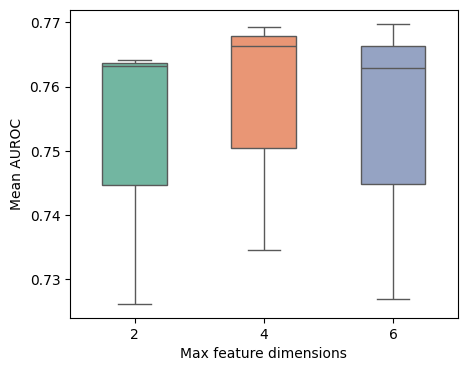

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
#fig, ax = plt.subplots(figsize=(6,5))
#sns.color_palette("pastel")
plt.figure(figsize=(5,4))
sns.boxplot(data=summary_results, x="batch_size", y='avg_aucroc_scores', hue="batch_size", palette="Set2", legend='auto', width=0.5)
plt.xlabel("Max feature dimensions")
plt.ylabel("Mean AUROC")
#plt.savefig('data_priors_impact.png')
#plt.savefig('data_priors_impact.png', dpi=300, bbox_inches='tight')

### Create Heatmap

In [15]:
df = pd.DataFrame(summary_dict)
# Create a pivot table
pivot_table = df.pivot_table(
    index='max_feat_dim',
    columns='batch_size',
    values='avg_aucroc_scores',
    aggfunc='mean'  # in case of duplicates
)

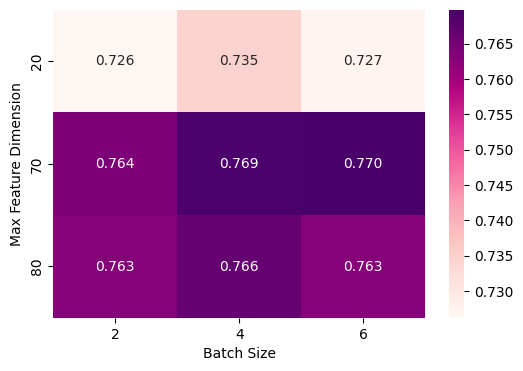

In [ ]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    pivot_table,
    annot=True,
    fmt=".3f",
    cmap="RdPu"   #"viridis"
)

#plt.title("Mean AUROC")
plt.xlabel("Batch Size")
plt.ylabel("Max Feature Dimension")
#plt.savefig('batch_mean_auroc_no_title.png', dpi=300, bbox_inches='tight')
plt.show()

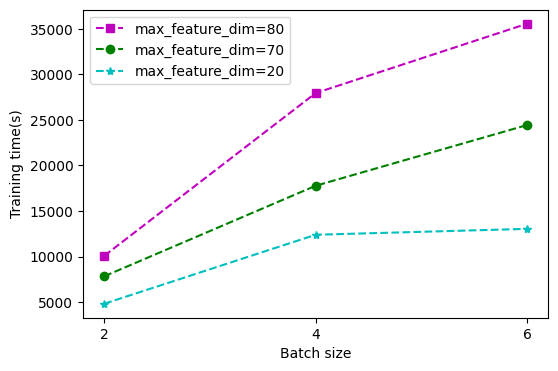

In [ ]:
max_feat_dim_80 = df[df['max_feat_dim'] == '80']
max_feat_dim_70 = df[df['max_feat_dim'] == '70']
max_feat_dim_20 = df[df['max_feat_dim'] == '20']

plt.figure(figsize=(6, 4))
plt.plot(max_feat_dim_80['batch_size'], max_feat_dim_80['training_time(s)'], marker='s', label='max_feature_dim=80', color='m', linestyle='dashed')
plt.plot(max_feat_dim_70['batch_size'], max_feat_dim_70['training_time(s)'], marker='o', label='max_feature_dim=70', color='green', linestyle='dashed')
plt.plot(max_feat_dim_20['batch_size'], max_feat_dim_20['training_time(s)'], marker='*', label='max_feature_dim=20', color='c', linestyle='dashed')

plt.xlabel('Batch size')
plt.ylabel('Training time(s)')
plt.legend()
#plt.savefig('batch_train_time.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
max_feat_dim_80 = df[df['max_feat_dim'] == '80']
max_feat_dim_70 = df[df['max_feat_dim'] == '70']
max_feat_dim_20 = df[df['max_feat_dim'] == '20']

,models,max_feat_dim,batch_size,avg_aucroc_scores,average_aucpr,average_f1,training_time(s),inference_time(µs)
0,Model_1,80,2,0.7632,0.4394,0.4465,10079.90,4.938331
1,Model_2,80,4,0.7664,0.4411,0.4421,27951.30,5.023406
2,Model_3,80,6,0.7629,0.4435,0.4462,35570.75,5.075239


In [31]:
summary_results

,models,max_feat_dim,batch_size,avg_aucroc_scores,average_aucpr,average_f1,training_time(s),inference_time(µs)
0,Model_1,80,2,0.7632,0.4394,0.4465,10079.90,4.938331
1,Model_2,80,4,0.7664,0.4411,0.4421,27951.30,5.023406
2,Model_3,80,6,0.7629,0.4435,0.4462,35570.75,5.075239
3,Model_7,70,2,0.7641,0.4452,0.4448,7831.28,4.891524
4,Model_8,70,4,0.7693,0.4491,0.4494,17772.96,5.099698
5,Model_9,70,6,0.7698,0.4490,0.4498,24438.82,5.110644
6,Model_4,20,2,0.7262,0.4352,0.4278,4814.38,4.871212
7,Model_5,20,4,0.7345,0.4080,0.4085,12389.38,5.034104
8,Model_6,20,6,0.7269,0.3991,0.3917,13037.65,4.908101
